# Данные для Reels Router

Reels Router должен находить места из туристических роликов и составлять из них маршрут. Для этого понадобятся тексты с упоминаниями мест и справочник с названиями, категориями и координатами.

Давайте рассмотрим три источника такого справочника: Overture, OpenStreetMap и Wikidata. Для примера возьмём центр Петербурга. Посмотрим, как устроены записи, насколько хорошо заполнены поля и какие данные пригодятся для поиска и обучения. Затем сравним их с Audiala, Samuel & Audrey, MTD-GEM и CityGuessr.

Данные выгружены 27 октября 2026 года.

In [1]:
from pathlib import Path
from collections import Counter
from difflib import SequenceMatcher
import json, math, re, unicodedata
import xml.etree.ElementTree as ET
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
assert (ROOT / 'data/raw/overture_spb.geojson').exists(), 'Откройте ноутбук из папки poi_sources_demo'
def read(name): return json.loads((ROOT / name).read_text(encoding='utf-8'))
def read_lines(name): return [json.loads(x) for x in (ROOT/name).read_text(encoding='utf-8').splitlines()]
def write_json(name, obj):
    path = ROOT/name; path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding='utf-8')
def write_lines(name, rows):
    path = ROOT/name; path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(''.join(json.dumps(x, ensure_ascii=False)+'\n' for x in rows), encoding='utf-8')
def normalize(value):
    value = unicodedata.normalize('NFD', value.casefold().replace('ё', 'е'))
    value = ''.join(c for c in value if unicodedata.category(c) != 'Mn')
    return ' '.join(re.findall(r'\w+', value))
def distance_m(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(math.radians, [lon1, lat1, lon2, lat2])
    h = math.sin((lat2-lat1)/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin((lon2-lon1)/2)**2
    return 6371000*2*math.asin(min(1, math.sqrt(h)))

manifest = read('download_manifest.json')
overture_raw = read('data/raw/overture_spb.geojson')['features']
osm_raw = read('data/raw/osm_spb.json')['elements']
wikidata_raw = read('data/raw/wikidata_osm_linked.json')['entities']
pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'font.family':'DejaVu Sans', 'axes.spines.top':False, 'axes.spines.right':False})
print('Загружены данные Overture, OSM и Wikidata.')

Загружены данные Overture, OSM и Wikidata.


## 1. Объём данных

В релизе **Overture Places** от 21 октября 2026 года содержится **88 418 121 запись**. Это число опубликовано в [описании релиза](https://docs.overturemaps.org/blog/2026/10/21/release-notes/). Вместе с данными доступен каталог файлов STAC: в нём указаны размеры файлов и количество строк. Давайте посчитаем по нему общий объём и сравним с нашей выборкой.

В **OpenStreetMap** объекты представлены точками, контурами и группами связанных элементов. Например, контур музея состоит из нескольких точек, а его вход может быть отдельным объектом. Для получения справочника нужно выбрать территорию и категории мест. В выгрузке участка возле Эрмитажа содержится 5 828 элементов карты.

**Wikidata** содержит сведения о местах, людях, произведениях и других сущностях. На [странице статистики](https://www.wikidata.org/wiki/Special:Statistics) указано около 123,8 млн содержательных страниц. Для нашего примера возьмём 14 сущностей, на которые ссылаются объекты из OSM.

In [2]:
stac = pq.read_table(ROOT/'data/raw/overture_stac_collections.parquet').to_pylist()
place_files = [r for r in stac if r.get('collection') == 'place' and r['type'] == 'Feature']
global_rows = sum(r['num_rows'] for r in place_files)
global_bytes = sum(r['assets']['aws']['file:size'] for r in place_files)
assert global_rows == read('source_scale_facts.json')['overture_rows_release_notes']
display(pd.DataFrame([
    {'Объём':'Полный Overture Places', 'Записей':global_rows, 'Файлов':len(place_files), 'Размер, GB':round(global_bytes/1e9,3)},
    {'Объём':'Наша выборка Overture', 'Записей':len(overture_raw), 'Файлов':1, 'Размер, GB':round((ROOT/'data/raw/overture_spb.geojson').stat().st_size/1e9,3)}
]))
files = pd.DataFrame([{'Файл':x['file'], 'MB':round(x['bytes']/1e6,3), 'Примечание':x.get('selection',x.get('kind',''))} for x in manifest])
display(files)
total_raw = read('source_scale_facts.json')
print('Сохранённые raw двух исследований:', round((total_raw['earlier_raw_bytes']+total_raw['poi_raw_bytes'])/1e6,1), 'MB')
print('Размер включает исходные архивы и распакованные файлы.')

,Объём,Записей,Файлов,"Размер, GB"
0,Полный Overture Places,88418121,16,11.896
1,Наша выборка Overture,14784,1,0.035


,Файл,MB,Примечание
0,data/raw/overture_catalog.json,0.009,
1,data/raw/overture_stac_collections.parquet,0.149,"global file index, not global POI data"
2,data/raw/overture_spb.geojson,34.783,all place categories in bbox
3,data/raw/osm_hermitage_area.osm,2.755,
4,data/raw/osm_spb.json,0.034,tourism attraction/museum/gallery/viewpoint; amenity cafe/restaurant/theatre/arts_cent...
5,data/raw/wikidata_osm_linked.json,0.717,"OSM wikidata tag join, not independent geographical search"


Сохранённые raw двух исследований: 587.9 MB
Размер включает исходные архивы и распакованные файлы.


Полный релиз Places занимает **11,90 ГБ в 16 сжатых файлах Parquet**. Наша выборка из 14 784 записей сохранена в GeoJSON и занимает 34,78 МБ.

В выборку Overture входит центр Петербурга: от 30.27 до 30.36 по долготе и от 59.915 до 59.955 по широте. В ней представлены все категории, включая школы, магазины, гостиницы и услуги.

Для OSM выгружен небольшой участок возле Эрмитажа. Его границы показаны на графике. При дальнейшем сравнении нужно учитывать разницу территорий: данные OSM здесь охватывают лишь часть выборки Overture.

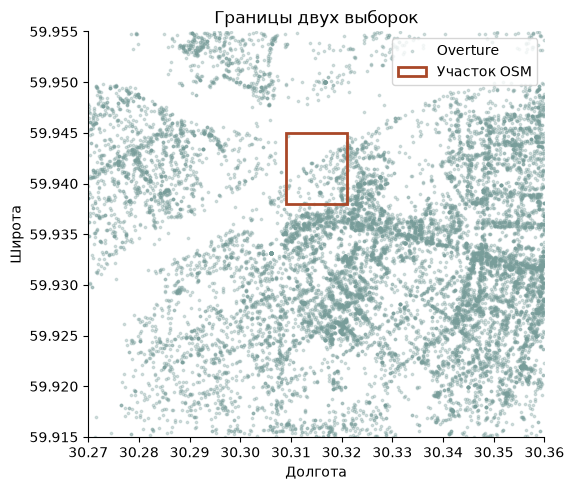

In [3]:
fig, ax = plt.subplots(figsize=(9,5))
coords = [f['geometry']['coordinates'] for f in overture_raw]
ax.scatter([p[0] for p in coords], [p[1] for p in coords], s=3, alpha=.3, color='#789d9a', label='Overture')
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((30.309,59.938),.012,.007,fill=False,edgecolor='#a94828',lw=2,label='Участок OSM'))
ax.set(xlim=(30.27,30.36),ylim=(59.915,59.955),xlabel='Долгота',ylabel='Широта',title='Границы двух выборок')
ax.set_aspect(2);ax.legend();fig.tight_layout();plt.show()

## 2. Структура записей

В **Overture** каждая запись содержит точку на карте и сведения о месте:

| Поле | Содержание |
|---|---|
| `id` | Идентификатор записи |
| `names` | Основное название и другие варианты |
| `basic_category` | Категория, например museum или cafe |
| `taxonomy` | Категория и её положение в общей классификации |
| `addresses`, `websites` | Адреса и сайты |
| `confidence` | Оценка уверенности источника в существовании места |
| `operating_status` | Сведения о том, работает ли организация или закрыта |

Описание полей доступно в [документации Places](https://docs.overturemaps.org/schema/reference/places/place/).

В **OSM** свойства объекта хранятся в тегах. Для поиска пригодятся `name`, языковые варианты `name:ru` и `name:en`, альтернативное название `alt_name`, адрес и ссылка `wikidata`. Музей, здание музея и вход могут иметь отдельные записи.

В **Wikidata** идентификатор QID связывает названия на разных языках, альтернативные названия и описание одной сущности. Координаты хранятся в свойстве P625, ссылка на имя файла изображения в P18, тип сущности в P31.

Давайте посмотрим несколько записей Overture.

In [4]:
ov_rows = []
for f in overture_raw:
    p = f['properties']; names = p.get('names') or {}; taxonomy = p.get('taxonomy') or {}
    common = list((names.get('common') or {}).values())
    alternatives = common + [r.get('value','') for r in names.get('rules') or []]
    aliases = list(dict.fromkeys(v for v in alternatives if isinstance(v,str) and v and normalize(v)!=normalize(names.get('primary') or '')))
    address = p.get('addresses') or []
    providers = [s.get('dataset') for s in p.get('sources') or [] if s.get('property') == '']
    ov_rows.append({'id':p['id'], 'name':names.get('primary') or '', 'aliases':aliases,
        'category':p.get('basic_category'), 'top_category':(taxonomy.get('hierarchy') or [None])[0],
        'lon':f['geometry']['coordinates'][0], 'lat':f['geometry']['coordinates'][1],
        'address':'; '.join(a.get('freeform') or '' for a in address),
        'website':p.get('websites') or [], 'operating_status':p.get('operating_status'),
        'confidence':p.get('confidence'), 'provider':'; '.join(providers)})
ov = pd.DataFrame(ov_rows)
sample_ids = ['c4009d88-e788-4b7a-be85-11b2700192ca','416f222f-3221-40e2-96b5-d37d0148f386',
              '876ff195-51d1-441b-9f22-4ea424d81fe8','fb5df4e6-f8a9-4dd1-8f4d-aa5ae11abe8e']
display(ov.loc[ov.id.isin(sample_ids),['name','category','address','lat','lon','provider']])

,name,category,address,lat,lon,provider
442,New Holland Island,historic_site,набережная Адмиралтейского канала 2,59.929216,30.287952,meta
1670,Новая Голландия,bar,площадь Труда,59.927779,30.293724,meta
12674,Государственный Эрмитаж - The State Hermitage Museum,museum,Дворцовая набережная 34,59.941173,30.313721,meta
13896,Эрмитаж Свадебная и Вечерняя Мода,fashion_and_apparel_store,Фурштатская улица,59.945155,30.349659,meta


Среди этих примеров есть Государственный Эрмитаж, магазин с названием «Эрмитаж», остров Новая Голландия и одноимённый бар. При поиске места из ролика такие записи могут попасть в одну выдачу. Разобраться помогут категория, адрес и контекст упоминания.

## 3. Заполненность полей

Давайте посмотрим, какие сведения доступны в выборке. Имя и координаты нужны для поиска и отображения точки. Категория помогает различать типы мест, адрес помогает выбирать среди одноимённых заведений, а варианты названия позволяют искать по разговорным и иностранным формам.

Посчитаем пустые значения в каждом поле. К ним относятся null, пустые строки и пустые списки.

In [5]:
def empty(v):
    return v is None or (isinstance(v,float) and math.isnan(v)) or (isinstance(v,(str,list,dict)) and len(v)==0)
completeness = pd.DataFrame([
    {'Поле':col,'Пустых':sum(empty(v) for v in ov[col]),'Доля, %':round(100*sum(empty(v) for v in ov[col])/len(ov),2)}
    for col in ['name','lat','lon','category','top_category','aliases','address','website','operating_status']
])
display(completeness)
display(ov.groupby('provider').agg(records=('id','size'),median_confidence=('confidence','median')).sort_values('records',ascending=False))
print('Уникальных ID:',ov.id.nunique(),'; строк:',len(ov))
print('Неверный диапазон координат:',int((~ov.lat.between(-90,90) | ~ov.lon.between(-180,180)).sum()))
print('Координаты (0,0):',int(((ov.lat==0)&(ov.lon==0)).sum()))

,Поле,Пустых,"Доля, %"
0,name,0,0.00
1,lat,0,0.00
2,lon,0,0.00
3,category,331,2.24
4,top_category,347,2.35
5,aliases,14661,99.17
6,address,907,6.14
7,website,4084,27.62
8,operating_status,14784,100.00


,records,median_confidence
provider,,
meta,12142,0.6626
Foursquare,2250,0.7700
AllThePlaces,350,0.8000
Microsoft,42,0.9655


Уникальных ID: 14784 ; строк: 14784
Неверный диапазон координат: 0
Координаты (0,0): 0


У всех **14 784 записей** есть имя и координаты. Категория отсутствует у **331 записи**, верхний уровень классификации `taxonomy` у **347**. Эти поля заполняются отдельно, поэтому число пропусков различается.

Другой вариант названия найден у **123 записей**. Для поиска по русским и разговорным названиям эту часть справочника стоит дополнить данными OSM и Wikidata.

Сайта нет у **4 084 записей**. Поле `operating_status` пустое во всей выборке, поэтому актуальность работы заведений придётся уточнять отдельно. Большая часть записей этого района поступила от Meta.

Все координаты находятся в допустимом диапазоне. Для объектов, которые попадут в маршрут, также потребуется уточнить положение на карте и найти вход.

## 4. Выборки для прогулок и остановок поесть

Давайте посмотрим распределение категорий и выделим две группы. Для прогулок возьмём музеи, исторические места, памятники, галереи, парки и сады. Для остановок поесть выберем раздел `food_and_drink`.

Полную выборку сохраним для общего поиска. Она пригодится, например, если в ролике рекомендуют гостиницу или магазин.

,Записей
category,
restaurant,1342
fashion_and_apparel_store,879
bar,731
hotel,722
personal_or_beauty_service,713
shopping,453
historic_site,452
coffee_shop,448
cafe,439


,Для чего,Записей,Правило
0,Все кандидаты по имени,14784,Все именованные записи с координатами
1,Достопримечательности и прогулки,1040,"art_gallery, castle, garden, historic_site, monument, museum, park, sculpture_statue, ..."
2,Еда и напитки,3492,taxonomy.hierarchy[0] == food_and_drink


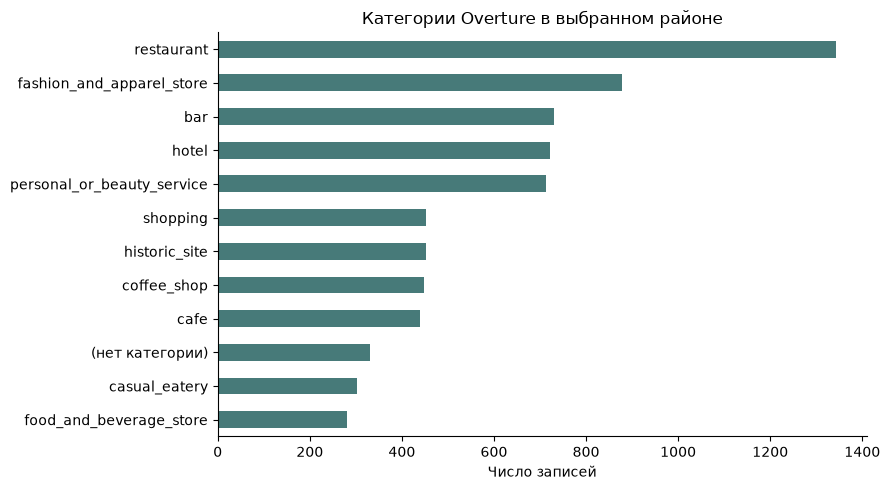

In [6]:
counts = ov.category.fillna('(нет категории)').value_counts()
display(counts.head(15).rename('Записей').to_frame())
sightseeing_categories = {'historic_site','museum','monument','art_gallery','park','garden','sculpture_statue','street_art','castle'}
sightseeing = ov[ov.category.isin(sightseeing_categories)]
food = ov[ov.top_category.eq('food_and_drink')]
display(pd.DataFrame([
    {'Для чего':'Все кандидаты по имени','Записей':len(ov),'Правило':'Все именованные записи с координатами'},
    {'Для чего':'Достопримечательности и прогулки','Записей':len(sightseeing),'Правило':', '.join(sorted(sightseeing_categories))},
    {'Для чего':'Еда и напитки','Записей':len(food),'Правило':'taxonomy.hierarchy[0] == food_and_drink'}
]))
sight_ids=set(sightseeing.id); food_ids=set(food.id)
# Сохраним записи вместе с исходными полями и сведениями об источниках.
write_lines('data/usable/overture_sightseeing.jsonl',[f for f in overture_raw if f['properties']['id'] in sight_ids])
write_lines('data/usable/overture_food_drink.jsonl',[f for f in overture_raw if f['properties']['id'] in food_ids])
fig,ax=plt.subplots(figsize=(9,5));counts.head(12).iloc[::-1].plot.barh(ax=ax,color='#477a79')
ax.set(xlabel='Число записей',ylabel='',title='Категории Overture в выбранном районе');fig.tight_layout();plt.show()

Получилось **1 040 записей достопримечательностей** и **3 492 записи еды и напитков**. Обе выборки сохранены в `data/usable/` и подходят для первого поискового индекса.

Далее разберём повторяющиеся названия и возможные дубли. Для маршрута к выбранным объектам также понадобятся сведения о входах, доступности прохода и часах работы.

## 5. Повторяющиеся названия

Давайте приведём названия к одному виду: уберём различия в регистре, ударения и пунктуацию, заменим ё на е. Затем посчитаем повторы.

Одинаковые имена могут встречаться у филиалов сети, разных заведений и нескольких записей одного объекта. Чтобы различить эти случаи, рассмотрим адреса и координаты.

In [7]:
ov['normalized_name'] = ov.name.map(normalize)
repeated = ov.normalized_name.value_counts()
repeated = repeated[repeated>1]
print('Повторяющихся имён:',len(repeated),'; строк с такими именами:',int(repeated.sum()))
display(repeated.head(12).rename('Строк').to_frame())
example = ov[ov.id.isin(['416f222f-3221-40e2-96b5-d37d0148f386','876ff195-51d1-441b-9f22-4ea424d81fe8','be78468a-04ca-49ac-996b-70ef0e0f86e3'])]
display(example[['id','name','category','lat','lon','confidence']])
island = example[example.name.eq('New Holland Island')]
a,b = island.iloc[0], island.iloc[1]
print('Расстояние между двумя записями New Holland Island, м:',round(distance_m(a.lon,a.lat,b.lon,b.lat)))

Повторяющихся имён: 847 ; строк с такими именами: 2505


,Строк
normalized_name,
wildberries,106
дикси,55
хлебник,32
ароматныи мир,26
теремок,25
baggins coffee,23
булочная ф вольчека,19
евразия,18
пятерочка,17


,id,name,category,lat,lon,confidence
442,876ff195-51d1-441b-9f22-4ea424d81fe8,New Holland Island,historic_site,59.929216,30.287952,0.759048
472,be78468a-04ca-49ac-996b-70ef0e0f86e3,New Holland Island,historic_site,59.929000,30.290000,0.771291
1670,416f222f-3221-40e2-96b5-d37d0148f386,Новая Голландия,bar,59.927779,30.293724,0.527258


Расстояние между двумя записями New Holland Island, м: 117


В выборке **847 повторяющихся названий**, которые встречаются в **2 505 строках**.

У Новой Голландии есть две записи `New Holland Island` с категорией `historic_site`. Русское название «Новая Голландия» относится к записи категории `bar`. Поиску понадобятся дополнительные варианты названий и контекст ролика, чтобы связать фразу с островом или заведением.

Две записи острова стоит сопоставить по координатам, адресу и сайту. После подтверждения их можно объединить в один объект справочника.

## 6. Отбор объектов OpenStreetMap

Давайте выберем из 5 828 элементов карты места, которые могут встретиться в туристических роликах:

- достопримечательности, музеи, галереи и обзорные точки;
- кафе, рестораны, театры и культурные центры;
- исторические объекты;
- парки и сады.

Отбор по тегам оставляет **50 записей**. Для точечных объектов возьмём их координаты. Для зданий и других составных объектов рассчитаем центр прямоугольника, охватывающего геометрию. Такую точку можно показать на карте; вход для маршрута потребуется определить отдельно.

In [8]:
xml = ET.parse(ROOT/'data/raw/osm_hermitage_area.osm').getroot()
raw_count = sum(e.tag in {'node','way','relation'} for e in xml)
osm_rows=[]
for e in osm_raw:
    t=e['tags']; c=e if e['type']=='node' else e.get('center',{})
    osm_rows.append({'id':f"osm/{e['type']}/{e['id']}", 'name':t.get('name') or t.get('name:ru') or t.get('name:en') or '',
        'category':next((t[k] for k in ['tourism','amenity','historic','leisure'] if k in t),None),
        'lat':c.get('lat'),'lon':c.get('lon'),'wikidata':t.get('wikidata'),
        'complete':e['geometry_complete'],'inside':e['representative_point_in_bbox'],'tags':t})
osm=pd.DataFrame(osm_rows)
inside=osm[osm.complete & osm.inside].copy()
named=inside[inside.name.ne('')].copy()
display(pd.DataFrame({'Этап':['Элементы XML','Подходят по тегам','Полная геометрия','Точка внутри участка','Есть имя и точка внутри'],
    'Записей':[raw_count,len(osm),int(osm.complete.sum()),len(inside),len(named)]}))
display(osm.loc[~osm.complete | ~osm.inside,['id','name','category','complete','inside']])

,Этап,Записей
0,Элементы XML,5828
1,Подходят по тегам,50
2,Полная геометрия,47
3,Точка внутри участка,43
4,Есть имя и точка внутри,35


,id,name,category,complete,inside
18,osm/node/6482673282,Пушкинское место,memorial,True,False
23,osm/node/7692396409,,memorial,True,False
36,osm/way/100549426,Музей-квартира А. С. Пушкина,museum,True,False
43,osm/relation/1604351,Александровский сад,park,True,False
45,osm/relation/2612859,Адмиралтейство,attraction,False,False
46,osm/relation/7294613,From the Varangians to the Greeks,trade_route,False,False
49,osm/relation/11492646,Адмиралтейский сад,park,False,False


У трёх объектов часть геометрии отсутствует в выгрузке. Ещё четыре находятся за границами выбранного участка. После их исключения остаются **43 записи**, из которых **35 имеют название**.

В отбор исторических объектов попал «Путь из варяг в греки». Это протяжённый маршрут, поэтому для списка остановок нужно сузить условие `historic=*`. Мемориальные доски и другие небольшие объекты можно оставить для тематических прогулок.

## 7. Названия и описания из Wikidata

В 50 записях OSM нашлись ссылки на **14 сущностей Wikidata**. Давайте добавим их русские и английские названия, альтернативные формы и описания.

Используем актуальные значения свойств, исключив утверждения с пометкой deprecated. Если у сущности несколько координат, сохраним их все для дальнейшего сопоставления.

In [9]:
def property_values(entity, prop):
    return [c['mainsnak']['datavalue']['value'] for c in entity.get('claims',{}).get(prop,[])
            if c.get('rank')!='deprecated' and c.get('mainsnak',{}).get('snaktype')=='value' and 'datavalue' in c['mainsnak']]
wd={}
for q,e in wikidata_raw.items():
    wd[q]={'ru':e.get('labels',{}).get('ru',{}).get('value',''),
        'en':e.get('labels',{}).get('en',{}).get('value',''),
        'aliases_ru':[a['value'] for a in e.get('aliases',{}).get('ru',[])],
        'aliases_en':[a['value'] for a in e.get('aliases',{}).get('en',[])],
        'description_ru':e.get('descriptions',{}).get('ru',{}).get('value',''),
        'coordinates':[v for v in property_values(e,'P625') if isinstance(v,dict) and v.get('globe','').endswith('/Q2')],
        'image_files':property_values(e,'P18')}
display(pd.DataFrame([{'qid':q,'ru':v['ru'],'en':v['en'],'aliases_ru':'; '.join(v['aliases_ru'])}
    for q,v in wd.items() if q in ['Q132783','Q907366','Q586283','Q2622043']]))
display(pd.DataFrame([{'Поле':k,'С заполненным полем':sum(bool(v[k]) for v in wd.values()),'Всего':len(wd)}
    for k in ['ru','en','aliases_ru','description_ru','coordinates','image_files']]))
print('Явных алиасов ru/en:',sum(len(v['aliases_ru'])+len(v['aliases_en']) for v in wd.values()))
display(osm.loc[osm.wikidata.eq('Q2622043'),['name','wikidata']])
print('Название в Wikidata:',wd['Q2622043']['ru'])

,qid,ru,en,aliases_ru
0,Q132783,Эрмитаж,Hermitage Museum,Государственный Эрмитаж; Императорский Эрмитаж
1,Q586283,Государственная академическая капелла Санкт-Петербурга,Saint Petersburg Court Capella,Придворная певческая капелла
2,Q907366,Александровская колонна,Alexander Column,Александрийская колонна; Алекса́ндровская коло́нна
3,Q2622043,Здание Главного штаба,"General Staff Building, Saint Petersburg",Главный штаб; Здание Государственного штаба; Здание Генерального штаба; Арка Главного ...


,Поле,С заполненным полем,Всего
0,ru,14,14
1,en,14,14
2,aliases_ru,9,14
3,description_ru,9,14
4,coordinates,13,14
5,image_files,14,14


Явных алиасов ru/en: 34


,name,wikidata
38,Восточное крыло Главного штаба,Q2622043


Название в Wikidata: Здание Главного штаба


Русское название есть у всех 14 сущностей, описание у девяти, координаты у 13. Всего найдено **34 альтернативных названия** на русском и английском.

Например, «Эрмитаж» и «Императорский Эрмитаж» относятся к одному QID. Название «Александрийская колонна» связано с Александровской колонной. Такие варианты полезны для поиска по речи и подписям к роликам.

Есть связь, которую нужно уточнить при разметке: объект OSM «Восточное крыло Главного штаба» ссылается на всё «Здание Главного штаба» в Wikidata. Для проекта стоит заранее решить, насколько подробно указывать место: весь комплекс, отдельное здание или его часть.

Свойство P18 даёт имя файла изображения в Wikimedia Commons. В дальнейшем по нему можно получить фотографии для визуальной части проекта с учётом лицензии каждого файла.

## 8. Поиск по имени и его вариантам

Давайте сравним два способа поиска: по основному имени и по имени вместе с альтернативными названиями. Для начала используем символьное сходство `SequenceMatcher`. Значение 1 соответствует полному совпадению текста.

Возьмём пять запросов из рассмотренных примеров и посмотрим первые результаты. Это позволит увидеть, где помогают дополнительные названия и какие неоднозначности остаются.

In [10]:
search=[]
for r in named.to_dict('records'):
    variants=[]
    for k,v in r['tags'].items():
        if k.startswith('name:') or k in ['alt_name','old_name','short_name','official_name','loc_name','int_name']:
            variants.extend(v.split(';'))
    entity=wd.get(r['wikidata'],{})
    variants += [entity.get('ru',''),entity.get('en','')] + entity.get('aliases_ru',[]) + entity.get('aliases_en',[])
    aliases=list(dict.fromkeys(v for v in variants if v and normalize(v)!=normalize(r['name'])))
    search.append({'id':r['id'],'name':r['name'],'aliases':aliases,'category':r['category'],'source':'OSM'})
search += [{'id':'overture/'+r['id'],'name':r['name'],'aliases':r['aliases'],'category':r['category'],'source':'Overture'} for r in ov_rows]
def retrieve(query, use_aliases, k=3):
    q=normalize(query); scored=[]
    for r in search:
        variants=[r['name']]+(r['aliases'] if use_aliases else [])
        score,match=max((SequenceMatcher(None,q,normalize(v)).ratio(),v) for v in variants)
        scored.append({**r,'score':score,'matched':match})
    return sorted(scored,key=lambda r:(-r['score'],r['id']))[:k]
queries=['Эрмитаж','Придворная певческая капелла','Александрийская колонна','Зимний дворец','Новая Голландия']
comparison=[]
for q in queries:
    for use_aliases in [False,True]:
        for rank,r in enumerate(retrieve(q,use_aliases),1):
            comparison.append({'Запрос':q,'Алиасы':use_aliases,'Место в выдаче':rank,'Название':r['name'],
                'Категория':r['category'],'Источник':r['source'],'Сходство':round(r['score'],3),'Совпавший вариант':r['matched']})
comparison=pd.DataFrame(comparison)
display(comparison[comparison['Место в выдаче'].eq(1)])
display(comparison[comparison['Запрос'].eq('Новая Голландия') & comparison['Алиасы']])
write_json('tables/name_vs_alias_search.json',comparison.to_dict('records'))

,Запрос,Алиасы,Место в выдаче,Название,Категория,Источник,Сходство,Совпавший вариант
0,Эрмитаж,False,1,У Эрмитажа,lodging,Overture,0.824,У Эрмитажа
3,Эрмитаж,True,1,Государственный Эрмитаж,museum,OSM,1.000,Эрмитаж
6,Придворная певческая капелла,False,1,Придворная Певческая Капелла,arts_and_entertainment,Overture,1.000,Придворная Певческая Капелла
9,Придворная певческая капелла,True,1,Государственная академическая капелла Санкт-Петербурга,theatre,OSM,1.000,Придворная певческая капелла
12,Александрийская колонна,False,1,Александровская колонна,attraction,OSM,0.913,Александровская колонна
15,Александрийская колонна,True,1,Александровская колонна,attraction,OSM,1.000,Александрийская колонна
18,Зимний дворец,False,1,Зимний дворец,castle,OSM,1.000,Зимний дворец
21,Зимний дворец,True,1,Зимний дворец,castle,OSM,1.000,Зимний дворец
24,Новая Голландия,False,1,Новая Голландия,bar,Overture,1.000,Новая Голландия
27,Новая Голландия,True,1,Новая Голландия,bar,Overture,1.000,Новая Голландия


,Запрос,Алиасы,Место в выдаче,Название,Категория,Источник,Сходство,Совпавший вариант
27,Новая Голландия,True,1,Новая Голландия,bar,Overture,1.000,Новая Голландия
28,Новая Голландия,True,2,Голландия,hotel,Overture,0.750,Голландия
29,Новая Голландия,True,3,Rock the Cycle Новая Голландия,gym,Overture,0.667,Rock the Cycle Новая Голландия


Альтернативные названия помогают найти объект по короткой или исторической форме. В выдаче по «Новой Голландии» первым остаётся бар, а по «Зимнему дворцу» находятся несколько одинаково названных записей.

Следующим шагом добавим контекст упоминания и сведения о категории. При разборе результатов удобно отдельно отмечать два случая: нужное место отсутствует в выдаче или присутствует, но занимает низкую позицию. Это поможет понять, где расширять справочник, а где улучшать выбор кандидата.

## 9. Подготовка примеров для обучения

Из названий OSM и Wikidata собраны **70 пар** вида «вариант названия → объект» для десяти QID. Давайте удалим повторные пары после нормализации и посмотрим, как сущности распределились между обучающей и проверочной частями.

In [11]:
pairs=pd.DataFrame(read_lines('data/training/weak_positive_alias_pairs.jsonl'))
pairs['normalized_query']=pairs['query'].map(normalize)
duplicate_pairs=pairs.duplicated(['normalized_query','candidate_id'])
clean_pairs=pairs.loc[~duplicate_pairs].copy()
display(pairs[['query','candidate_name','qid','needs_manual_review']].head(8))
print('Исходных пар:',len(pairs),'; после удаления повторов:',len(clean_pairs),'; QID:',pairs.qid.nunique())
display(pairs.groupby('split_demo_only').agg(pairs=('query','size'),entities=('qid','nunique')))
write_lines('data/usable/weak_alias_pairs_deduplicated.jsonl',clean_pairs.to_dict('records'))

,query,candidate_name,qid,needs_manual_review
0,Academic Chapel,Государственная академическая капелла Санкт-Петербурга,Q586283,True
1,卡佩拉礼拜堂,Государственная академическая капелла Санкт-Петербурга,Q586283,True
2,Saint Petersburg Court Capella,Государственная академическая капелла Санкт-Петербурга,Q586283,True
3,Придворная певческая капелла,Государственная академическая капелла Санкт-Петербурга,Q586283,True
4,The Winter Palace of Peter the Great,Зимний дворец Петра I,Q4191996,True
5,Talvipalatsi,Зимний дворец Петра I,Q4191996,True
6,Palais d'hiver de Pierre le Grand,Зимний дворец Петра I,Q4191996,True
7,Peter I Winter Palace,Зимний дворец Петра I,Q4191996,True


Исходных пар: 70 ; после удаления повторов: 69 ; QID: 10


,pairs,entities
split_demo_only,,
train,66,9
validation,4,1


Остаётся **69 уникальных пар**. В обучающую часть попали девять сущностей, в проверочную одна. Для полноценного эксперимента выборку нужно расширить, особенно проверочную часть. У текущих пар сохранена пометка `needs_manual_review`.

Основная задача для такого набора состоит в сопоставлении упоминания с конкретным POI. К правильной паре добавим похожие неподходящие объекты: например, для фразы о музее предложим гостиницу с тем же именем. Затем дополним набор настоящими фразами из распознанной речи и текста на кадрах.

Отдельно можно обучать объединение дублей по названиям, адресам и координатам. Для этого нужны пары с метками «один объект» и «разные объекты». Для классификации типов мест пригодятся категории справочника; при обучении их следует использовать только как целевые метки.

Визуальной модели потребуются изображения или кадры с привязкой к POI. Для построения маршрута понадобятся выбранные места, входы и сеть дорог.

## 10. Остальные источники данных

Давайте сопоставим эти справочники с четырьмя наборами из первого исследования. Подробный разбор каждого находится в папке `dataset_research`. Здесь собраны их объёмы и возможное применение.

In [12]:
inventory=read('source_inventory.json')
display(pd.DataFrame([{'Источник':r['source'],'Доступно':r['available'],'Скачано':r['downloaded'],'Применение':r['use']} for r in inventory]))
prior=read('tables/earlier_eda_summary.json')
assert prior['audiala']['places']==33289 and prior['mtd']['documents']==88
assert prior['samuel']['segments']==233285 and prior['cityguessr']['metadata_rows']==68269

,Источник,Доступно,Скачано,Применение
0,Overture Places,88 418 121 запись в релизе 2026-10-21.0; точный объём Parquet считаем из STAC ниже,14 784 записи центра Петербурга; все категории,Каталог кандидатов для сопоставления упоминаний. Выборки достопримечательностей и заве...
1,OpenStreetMap,Мировая карта; общего числа POI нет без определения тегов и правил объединения объектов,5 828 элементов участка карты; 50 после отбора тегов; 43 с геометрией внутри; 35 из ни...,"Геометрия достопримечательностей, парки, имена, связи с Wikidata. Отдельно можно выгру..."
2,Wikidata,"123 765 672 content pages на странице статистики 27.10.2026; это все темы, не число мест",14 сущностей по QID из выбранных OSM-объектов,"Альтернативные названия, русский/английский, описания и связи объектов."
3,Audiala Places,"33 289 записей в скачанной версии, 93 страны, 1 363 пары страна-город","Весь GeoJSON; Россия 554, Петербург 120, Москва 352",Дополнительный каталог достопримечательностей; имена ru/en для поиска.
4,Samuel & Audrey,1 397 записей видео и 233 285 реплик в скачанном релизе,"Оба полных файла транскриптов; медиана последнего таймкода 10,18 мин",Реальные туристические фразы для проверки извлечения мест и ручной разметки упоминаний.
5,MTD-GEM,"88 статей, 9 934 упоминания; 1 074 FAC_NAME",Все 44 английские и 44 индонезийские статьи,Извлечение именованных мест из текста после восстановления привязки разметки.
6,CityGuessr68k,"68 269 примеров, 166 городов; на странице загрузки медиаархивы около 253 ГБ","Только метаданные: train 54 614, validation 13 655; архив 8,83 МБ",Возможный отдельный эксперимент по определению города после получения медиа.


**Samuel & Audrey.** Набор содержит 1 397 транскриптов и 233 285 реплик туристических видео на английском языке. Медиана последнего таймкода составляет 611,06 с, около 10 минут. У десяти записей реплики заканчиваются в пределах первой минуты.

В данных найдены 19 реплик нулевой длительности, 27 073 пересечения интервалов и 11 расхождений между полным текстом и текстом, собранным из реплик. Пересечения могут возникать при одновременном показе нескольких субтитров. Для эксперимента возьмём короткие окна текста и разметим упомянутые места. Все окна одного видео оставим в одной части выборки. Данные относятся к одному каналу; перенос на других авторов потребуется оценить отдельно. Лицензия: CC BY-NC 4.0.

**MTD-GEM.** В 88 туристических статьях размечены 9 934 упоминания, включая 1 074 названия объектов категории FAC_NAME. Языки корпуса: английский и индонезийский. У 1 409 имён возникло расхождение с прикреплённой строкой текста. Все эти имена присутствуют в соответствующих документах, поэтому перед обучением нужно восстановить их позиции.

В опыте со словарём 33 английские статьи использовались для сбора названий, 11 для оценки поиска. F1 составил 26,89% для множеств найденных имён на документ. Набор пригодится для извлечения названий из текста после исправления привязки разметки.

**Audiala.** Каталог содержит 33 289 записей с координатами, QID и названиями на разных языках. В нём 554 российских объекта, включая 120 в Петербурге и 352 в Москве. У 38 записей координаты равны (0,0); по 25 английских и русских названий пусты. Начнём с исключения таких строк и отбора нужного города.

При точном поиске английских названий FAC_NAME из MTD-GEM совпадения нашлись для 60 из 476 упоминаний. Чтобы расширить выдачу, пригодятся альтернативные названия и сведения о городе. Лицензия: CC BY 4.0 с атрибуцией Audiala.

**CityGuessr.** Доступны метаданные 68 269 примеров из 166 городов. Медиаархивы занимают около 253 ГБ; в локальном исследовании использованы метаданные. Набор можно рассмотреть для отдельной задачи определения города по кадрам.

Обучающие строки содержат 512 чисел, кодирующих географическую метку. При подготовке визуальной модели эти значения нужно исключить из входных признаков, иначе модель получит информацию об ответе. Также предстоит разобраться с одинаковыми номерами клипов в train и validation по самим медиафайлам.

Дополнительно рассмотрены описания GeoWebNews, GeoCorpora, ATD-MCL, 3MASSIV и GAMa. Для работы с ними потребуется отдельный отбор данных с учётом тематики и доступа. Подробности находятся в `search_register.json`. Для выгрузки из 2ГИС нужен ключ API.

## 11. Применение в Reels Router

| Часть проекта | Данные | Следующий шаг |
|---|---|---|
| Извлечение названий | Samuel & Audrey, MTD-GEM | Разметить фразы и восстановить позиции сущностей |
| Поиск вариантов названия | Wikidata, языковые теги OSM | Связать варианты с ID объектов |
| Поиск кандидатов на карте | Overture, OSM, Audiala | Добавить поиск по имени, категории и району |
| Выбор конкретного POI | Собственные ролики и пары «упоминание → объект» | Разметить правильные ответы и похожие неподходящие места |
| Построение маршрута | Выбранные POI, входы, сеть дорог | Рассчитать время переходов и порядок остановок |

Для начала возьмём **20-30 роликов одного города** и разберём их вручную. Для каждого сохраним текст упоминания, таймкод, источник текста и ID места. Также отметим, показано ли место в кадре, рекомендовано автором или просто упомянуто.

Затем посмотрим, находится ли нужный объект в справочнике, попадает ли он в первые несколько кандидатов и какой результат выбирает система. По этим примерам будет понятно, какие названия добавить и какие ошибки учитывать при обучении.

Для итоговой оценки соберём отдельную выборку с другими авторами и поездками. Ролики одной поездки и их репосты оставим в одной части данных.

In [13]:
results={
    'global_overture_rows':global_rows,'global_overture_parquet_bytes':global_bytes,'global_overture_files':len(place_files),
    'downloaded_overture':len(ov),'sightseeing_candidates':len(sightseeing),'food_drink_candidates':len(food),
    'osm_raw_elements':raw_count,'osm_selected':len(osm),'osm_in_bbox':len(inside),'osm_named_in_bbox':len(named),
    'wikidata_entities':len(wd),'weak_pairs_raw':len(pairs),'weak_pairs_unique_normalized':len(clean_pairs),
    'weak_pairs_entities':int(pairs.qid.nunique()),'repeated_name_keys':len(repeated),'rows_with_repeated_names':int(repeated.sum()),
    'completeness':completeness.to_dict('records'),'full_raw_bytes_two_studies':total_raw['earlier_raw_bytes']+total_raw['poi_raw_bytes']}
write_json('tables/extended_summary.json',results)
print('Сохранены extended_summary.json, сравнение поиска и три выборки в data/usable/.')

Сохранены extended_summary.json, сравнение поиска и три выборки в data/usable/.


## Файлы

- `data/raw/`: исходные выгрузки.
- `data/usable/`: выборки достопримечательностей, заведений и пар названий.
- `tables/`: результаты расчётов.
- `requirements.txt`: библиотеки для запуска ноутбука.

Чтобы повторить анализ, откройте ноутбук из папки `poi_sources_demo` и выполните ячейки по порядку.

Источники: © OpenStreetMap contributors, [ODbL 1.0](https://opendatacommons.org/licenses/odbl/1-0/); [Wikidata, CC0](https://www.wikidata.org/wiki/Wikidata:Data_access); [Overture и поставщики данных](https://docs.overturemaps.org/attribution/). Сведения о происхождении записей Overture сохранены в поле `sources`.